# Incrementalidade na prática

**Atribuição** responde por onde o cliente passou antes de comprar.
**Incrementalidade** responde quantas vendas a mais uma ação realmente causou.

Este notebook mostra a diferença com **dados sintéticos** (simulados, nenhum dado real de cliente), em três partes:

1. Um teste com grupo de controle (*holdout*): o caso do e-mail de oferta de crédito.
2. O que acontece quando o grupo de comparação não é sorteado (viés de seleção).
3. Um teste geográfico: regiões com e sem campanha, medido por diferença em diferenças.

A pergunta que guia tudo: **o que teria acontecido sem a ação?**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, CINZA, LARANJA = "#2f5d8a", "#9aa5b1", "#d9822b"

## 1. Teste com grupo de controle

Uma cooperativa tem 20 mil clientes e quer saber se um e-mail oferecendo crédito gera contratos.
Os clientes são **sorteados**: metade recebe o e-mail (tratamento), metade não recebe nada (controle).

Na simulação, cada cliente tem uma propensão própria de contratar (uns já estavam procurando crédito, outros não).
O e-mail soma **2 pontos percentuais** a essa propensão. Esse é o efeito verdadeiro, que normalmente não conhecemos.

In [2]:
N = 20_000
EFEITO_REAL = 0.02

# propensão de base: média ~6%, variando de cliente para cliente
propensao = rng.beta(2, 31, size=N)
recebeu = rng.random(N) < 0.5                 # sorteio
p_final = propensao + EFEITO_REAL * recebeu
contratou = rng.random(N) < p_final

df = pd.DataFrame({"recebeu_email": recebeu, "contratou": contratou})
resumo = (df.groupby("recebeu_email")["contratou"]
            .agg(clientes="size", contratos="sum", taxa="mean")
            .rename(index={False: "controle", True: "tratamento"}))
resumo["contratos por mil"] = (resumo["taxa"] * 1000).round(1)
resumo

,clientes,contratos,taxa,contratos por mil
recebeu_email,,,,
controle,9929,601,0.060530,60.5
tratamento,10071,815,0.080925,80.9


### O que a atribuição diz

Todo contrato fechado por quem recebeu o e-mail tem o e-mail no caminho. A atribuição dá **todos** esses contratos ao e-mail.

In [3]:
trat = resumo.loc["tratamento"]
ctrl = resumo.loc["controle"]

atribuidos = int(trat["contratos"])
incrementais = (trat["taxa"] - ctrl["taxa"]) * trat["clientes"]

# intervalo de 95% para a diferença de proporções
ep = np.sqrt(trat["taxa"]*(1-trat["taxa"])/trat["clientes"] + ctrl["taxa"]*(1-ctrl["taxa"])/ctrl["clientes"])
dif = trat["taxa"] - ctrl["taxa"]
ic = (dif - 1.96*ep, dif + 1.96*ep)

print(f"Contratos atribuídos ao e-mail:      {atribuidos:,}".replace(",", "."))
print(f"Contratos que o e-mail causou:       {incrementais:,.0f}".replace(",", "."))
print(f"Parte atribuída que já ia acontecer: {1 - incrementais/atribuidos:.0%}")
print(f"Efeito por cliente: {dif*100:.2f} p.p. (IC 95%: {ic[0]*100:.2f} a {ic[1]*100:.2f} p.p.) — verdadeiro: {EFEITO_REAL*100:.2f} p.p.")

Contratos atribuídos ao e-mail:      815
Contratos que o e-mail causou:       205
Parte atribuída que já ia acontecer: 75%
Efeito por cliente: 2.04 p.p. (IC 95%: 1.33 a 2.75 p.p.) — verdadeiro: 2.00 p.p.


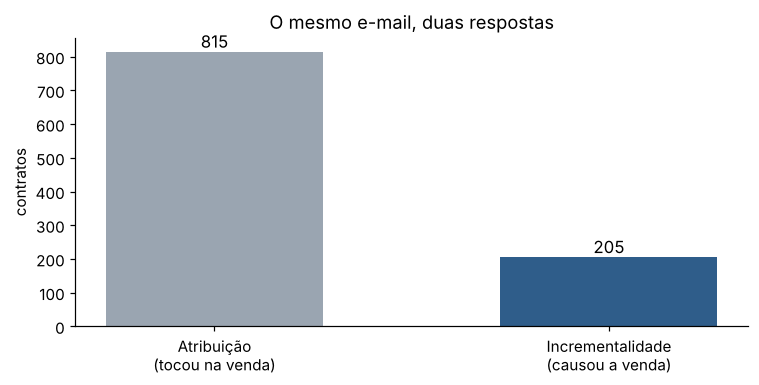

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
valores = [atribuidos, incrementais]
barras = ax.bar(["Atribuição\n(tocou na venda)", "Incrementalidade\n(causou a venda)"], valores, color=[CINZA, AZUL], width=0.55)
for b, v in zip(barras, valores):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:,.0f}".replace(",", "."), ha="center", va="bottom", fontsize=11)
ax.set_ylabel("contratos")
ax.set_title("O mesmo e-mail, duas respostas")
fig.tight_layout()
fig.savefig("figuras/atribuicao_vs_incrementalidade.png")
plt.show()

A atribuição não está "errada": ela descreve o caminho. O problema é usar o caminho como se fosse a **causa** na hora de decidir orçamento.
O grupo de controle mostra quantos contratos aconteceriam de qualquer jeito, e só a diferença é efeito do e-mail.

## 2. Quando o grupo de comparação não é sorteado

Na prática, é comum mandar o e-mail só para os clientes mais engajados e comparar com o resto.
Os engajados já contratam mais por conta própria, então a comparação mistura o efeito do e-mail com a diferença entre os grupos.

In [5]:
# envia para os 50% com maior propensão (os "engajados")
corte = np.quantile(propensao, 0.5)
recebeu_sel = propensao >= corte
contratou_sel = rng.random(N) < (propensao + EFEITO_REAL * recebeu_sel)

taxa_t = contratou_sel[recebeu_sel].mean()
taxa_c = contratou_sel[~recebeu_sel].mean()
print(f"Diferença observada sem sorteio: {(taxa_t - taxa_c)*100:.2f} p.p.")
print(f"Efeito verdadeiro:               {EFEITO_REAL*100:.2f} p.p.")
print(f"Superestimação:                  {(taxa_t - taxa_c)/EFEITO_REAL:.1f}x")

Diferença observada sem sorteio: 8.31 p.p.
Efeito verdadeiro:               2.00 p.p.
Superestimação:                  4.2x


Sem sorteio, a diferença parece várias vezes maior do que o efeito real. Por isso o grupo de controle precisa ser **parecido** com o tratado, e o jeito mais simples de garantir isso é sortear.

## 3. Teste geográfico

Nem toda ação permite separar clientes um a um (rádio, outdoor, mídia regional). Nesse caso, comparamos **regiões**.

Simulação: 30 regiões, vendas semanais por 12 semanas. Nas 8 primeiras ninguém tem campanha.
Nas 4 últimas, 15 regiões sorteadas recebem a campanha, que aumenta as vendas em **8%**.
Todas as regiões sofrem a mesma sazonalidade (as vendas sobem no fim do período, com ou sem campanha).

In [6]:
R, S, PRE = 30, 12, 8
LIFT_REAL = 0.08

base = rng.lognormal(mean=np.log(1000), sigma=0.35, size=R)          # tamanho de cada região
sazonal = 1 + 0.03*np.arange(S) + np.where(np.arange(S) >= PRE, 0.10, 0)  # todo mundo sobe no fim
campanha = np.zeros(R, dtype=bool)
campanha[rng.choice(R, R//2, replace=False)] = True

linhas = []
for r in range(R):
    for s in range(S):
        efeito = 1 + LIFT_REAL * (campanha[r] and s >= PRE)
        vendas = base[r] * sazonal[s] * efeito * rng.normal(1, 0.04)
        linhas.append((r, s+1, campanha[r], s >= PRE, vendas))
geo = pd.DataFrame(linhas, columns=["regiao", "semana", "campanha", "pos", "vendas"])
geo.head()

,regiao,semana,campanha,pos,vendas
0,0,1,False,False,868.959937
1,0,2,False,False,851.660173
2,0,3,False,False,864.973733
3,0,4,False,False,890.043269
4,0,5,False,False,958.611139


In [7]:
medias = geo.groupby(["campanha", "pos"])["vendas"].mean().unstack()
medias.columns = ["antes", "depois"]
medias.index = ["sem campanha", "com campanha"]
medias["variação"] = medias["depois"] / medias["antes"] - 1

antes_depois = medias.loc["com campanha", "variação"]
did = (1 + medias.loc["com campanha", "variação"]) / (1 + medias.loc["sem campanha", "variação"]) - 1

print(f"'Antes x depois' nas regiões com campanha: {antes_depois:+.1%}")
print(f"Diferença em diferenças (vs. regiões sem):  {did:+.1%}")
print(f"Efeito verdadeiro:                          {LIFT_REAL:+.1%}")
medias.style.format({"antes": "{:,.0f}", "depois": "{:,.0f}", "variação": "{:+.1%}"})

'Antes x depois' nas regiões com campanha: +35.4%
Diferença em diferenças (vs. regiões sem):  +8.7%
Efeito verdadeiro:                          +8.0%


,antes,depois,variação
sem campanha,970,"1,209",+24.6%
com campanha,"1,047","1,418",+35.4%


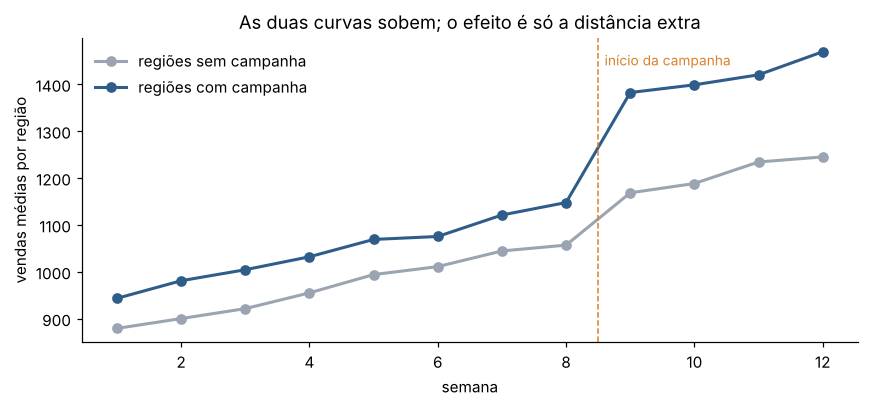

In [8]:
serie = geo.groupby(["semana", "campanha"])["vendas"].mean().unstack()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(serie.index, serie[False], color=CINZA, lw=2, marker="o", label="regiões sem campanha")
ax.plot(serie.index, serie[True], color=AZUL, lw=2, marker="o", label="regiões com campanha")
ax.axvline(PRE + 0.5, color=LARANJA, ls="--", lw=1)
ax.text(PRE + 0.6, ax.get_ylim()[1]*0.98, "início da campanha", color=LARANJA, va="top", fontsize=9)
ax.set_xlabel("semana"); ax.set_ylabel("vendas médias por região")
ax.set_title("As duas curvas sobem; o efeito é só a distância extra")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig("figuras/teste_geografico.png")
plt.show()

O "antes x depois" credita à campanha também a alta sazonal, que aconteceu em todo lugar.
A diferença em diferenças desconta essa alta usando as regiões sem campanha e chega perto do efeito verdadeiro.

## Resumo

| Pergunta | Método | Risco |
|---|---|---|
| Por onde o cliente passou? | Atribuição | Confundir caminho com causa |
| Quanto a ação causou? | Grupo de controle sorteado | Precisa reservar parte do público |
| Quanto a campanha regional causou? | Teste geográfico (diferença em diferenças) | Regiões precisam ter tendências parecidas antes |

A pergunta que muda o orçamento não é "quem tocou na venda?". É **"o que teria acontecido sem isso?"**.

---
Evandro de Melo · Cientista de Dados · [LinkedIn](https://www.linkedin.com/in/evandrodemelo/)